## 2012 NBA Finals Analysis: How the leBron James and the Miami Heat dominated

### This notebook is covers gathering the data for the analysis using pandas and numpy.

## Libaries used
### Pandas: Gathering matchup data and numbers from boxscores during the finals series to create hypotheses

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from nba_api.stats.endpoints import leaguegamefinder

print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("matplotlib:", plt.matplotlib.__version__)
print("seaborn:", sns.__version__)
print("All libraries loaded successfully!")

pandas: 3.0.3
numpy: 1.26.4
matplotlib: 3.7.0
seaborn: 0.13.2
All libraries loaded successfully!


In [3]:
from nba_api.stats.endpoints import leaguegamefinder
from nba_api.stats.static import teams
import time

nba_teams = teams.get_teams()
heat = [team for team in nba_teams if team['abbreviation'] == 'MIA'][0]
thunder = [team for team in nba_teams if team['abbreviation'] == 'OKC'][0]

print("Heat team info:", heat)
print("Thunder team info:", thunder)



Heat team info: {'id': 1610612748, 'full_name': 'Miami Heat', 'abbreviation': 'MIA', 'nickname': 'Heat', 'city': 'Miami', 'state': 'Florida', 'year_founded': 1988}
Thunder team info: {'id': 1610612760, 'full_name': 'Oklahoma City Thunder', 'abbreviation': 'OKC', 'nickname': 'Thunder', 'city': 'Oklahoma City', 'state': 'Oklahoma', 'year_founded': 1967}


In [4]:
gamefinder = leaguegamefinder.LeagueGameFinder(team_id_nullable=heat['id'], season_nullable='2011-12', season_type_nullable='Playoffs')

heat_playoffs = gamefinder.get_data_frames()[0]

print("Shape", heat_playoffs.shape)
print("\nColumns:", heat_playoffs.columns)
print("\nAll Heat playoff games:")
heat_playoffs

Shape (23, 28)

Columns: Index(['SEASON_ID', 'TEAM_ID', 'TEAM_ABBREVIATION', 'TEAM_NAME', 'GAME_ID',
       'GAME_DATE', 'MATCHUP', 'WL', 'MIN', 'PTS', 'FGM', 'FGA', 'FG_PCT',
       'FG3M', 'FG3A', 'FG3_PCT', 'FTM', 'FTA', 'FT_PCT', 'OREB', 'DREB',
       'REB', 'AST', 'STL', 'BLK', 'TOV', 'PF', 'PLUS_MINUS'],
      dtype='str')

All Heat playoff games:


,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,PTS,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PLUS_MINUS
0,42011,1610612748,MIA,Miami Heat,0041100405,2012-06-21,MIA vs. OKC,W,241,121,...,0.818,8,33,41,25,8,7,13,21,15.0
1,42011,1610612748,MIA,Miami Heat,0041100404,2012-06-19,MIA vs. OKC,W,239,104,...,0.720,9,31,40,19,8,2,9,18,6.0
2,42011,1610612748,MIA,Miami Heat,0041100403,2012-06-17,MIA vs. OKC,W,240,91,...,0.886,14,31,45,13,6,5,12,19,6.0
3,42011,1610612748,MIA,Miami Heat,0041100402,2012-06-14,MIA @ OKC,W,238,100,...,0.880,11,29,40,13,5,4,13,21,4.0
4,42011,1610612748,MIA,Miami Heat,0041100401,2012-06-12,MIA @ OKC,L,240,94,...,0.778,7,28,35,20,6,1,10,19,-11.0
5,42011,1610612748,MIA,Miami Heat,0041100307,2012-06-09,MIA vs. BOS,W,240,101,...,0.741,9,29,38,16,8,3,13,14,13.0
6,42011,1610612748,MIA,Miami Heat,0041100306,2012-06-07,MIA @ BOS,W,241,98,...,0.773,10,34,44,15,8,4,12,21,19.0
7,42011,1610612748,MIA,Miami Heat,0041100305,2012-06-05,MIA vs. BOS,L,239,90,...,0.760,12,37,49,13,6,3,15,21,-4.0
8,42011,1610612748,MIA,Miami Heat,0041100304,2012-06-03,MIA @ BOS,L,265,91,...,0.708,7,33,40,20,6,6,17,28,-2.0
9,42011,1610612748,MIA,Miami Heat,0041100303,2012-06-01,MIA @ BOS,L,241,91,...,0.500,6,26,32,20,5,5,10,24,-10.0


In [5]:
heat_playoffs.head()

,SEASON_ID,TEAM_ID,TEAM_ABBREVIATION,TEAM_NAME,GAME_ID,GAME_DATE,MATCHUP,WL,MIN,PTS,...,FT_PCT,OREB,DREB,REB,AST,STL,BLK,TOV,PF,PLUS_MINUS
0,42011,1610612748,MIA,Miami Heat,0041100405,2012-06-21,MIA vs. OKC,W,241,121,...,0.818,8,33,41,25,8,7,13,21,15.0
1,42011,1610612748,MIA,Miami Heat,0041100404,2012-06-19,MIA vs. OKC,W,239,104,...,0.720,9,31,40,19,8,2,9,18,6.0
2,42011,1610612748,MIA,Miami Heat,0041100403,2012-06-17,MIA vs. OKC,W,240,91,...,0.886,14,31,45,13,6,5,12,19,6.0
3,42011,1610612748,MIA,Miami Heat,0041100402,2012-06-14,MIA @ OKC,W,238,100,...,0.880,11,29,40,13,5,4,13,21,4.0
4,42011,1610612748,MIA,Miami Heat,0041100401,2012-06-12,MIA @ OKC,L,240,94,...,0.778,7,28,35,20,6,1,10,19,-11.0


In [6]:
finals_games = heat_playoffs[heat_playoffs['GAME_ID'].str.contains('0411004')]
finals_games[['GAME_ID', 'GAME_DATE', 'MATCHUP', 'WL']]

,GAME_ID,GAME_DATE,MATCHUP,WL
0,0041100405,2012-06-21,MIA vs. OKC,W
1,0041100404,2012-06-19,MIA vs. OKC,W
2,0041100403,2012-06-17,MIA vs. OKC,W
3,0041100402,2012-06-14,MIA @ OKC,W
4,0041100401,2012-06-12,MIA @ OKC,L


In [7]:
from nba_api.stats.endpoints import boxscoretraditionalv3
import time

# Good practice to pause between API calls to avoid hitting rate limits
time.sleep(1)

game1_id = finals_games[finals_games['GAME_ID'].str.endswith('401')]['GAME_ID'].values[0]
boxscore_game1 = boxscoretraditionalv3.BoxScoreTraditionalV3(game_id=game1_id)
boxscore_game1.get_data_frames()

[        gameId      teamId       teamCity teamName teamTricode teamSlug  \
 0   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 1   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 2   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 3   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 4   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 5   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 6   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 7   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 8   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 9   0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 10  0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 11  0041100401  1610612760  Oklahoma City  Thunder         OKC  thunder   
 12  0041100

In [8]:
game_level_boxscores = []
for game_id in finals_games['GAME_ID']:
    print("Fetching box score for game ID:", game_id)
    boxscore = boxscoretraditionalv3.BoxScoreTraditionalV3(game_id=game_id)
    game_level_boxscore = boxscore.get_data_frames()[0]
    game_level_boxscore['GAME_NUMBER'] = int(game_id[-1])
    game_level_boxscores.append(game_level_boxscore)
    time.sleep(1)

Fetching box score for game ID: 0041100405
Fetching box score for game ID: 0041100404
Fetching box score for game ID: 0041100403
Fetching box score for game ID: 0041100402
Fetching box score for game ID: 0041100401


In [9]:
all_games_df = pd.concat(game_level_boxscores, ignore_index=True)
print(all_games_df.head())


       gameId      teamId teamCity teamName teamTricode teamSlug  personId  \
0  0041100405  1610612748    Miami     Heat         MIA     heat      2544   
1  0041100405  1610612748    Miami     Heat         MIA     heat      2203   
2  0041100405  1610612748    Miami     Heat         MIA     heat      2547   
3  0041100405  1610612748    Miami     Heat         MIA     heat      2548   
4  0041100405  1610612748    Miami     Heat         MIA     heat    201596   

  firstName familyName        nameI  ... reboundsDefensive reboundsTotal  \
0    LeBron      James     L. James  ...                 7            11   
1     Shane    Battier   S. Battier  ...                 4             4   
2     Chris       Bosh      C. Bosh  ...                 7             7   
3    Dwyane       Wade      D. Wade  ...                 6             8   
4     Mario   Chalmers  M. Chalmers  ...                 1             2   

  assists steals blocks  turnovers  foulsPersonal  points  plusMinusPoints

In [10]:
print("Columns in the combined box score DataFrame:", all_games_df.columns)

Columns in the combined box score DataFrame: Index(['gameId', 'teamId', 'teamCity', 'teamName', 'teamTricode', 'teamSlug',
       'personId', 'firstName', 'familyName', 'nameI', 'playerSlug',
       'position', 'comment', 'jerseyNum', 'minutes', 'fieldGoalsMade',
       'fieldGoalsAttempted', 'fieldGoalsPercentage', 'threePointersMade',
       'threePointersAttempted', 'threePointersPercentage', 'freeThrowsMade',
       'freeThrowsAttempted', 'freeThrowsPercentage', 'reboundsOffensive',
       'reboundsDefensive', 'reboundsTotal', 'assists', 'steals', 'blocks',
       'turnovers', 'foulsPersonal', 'points', 'plusMinusPoints',
       'GAME_NUMBER'],
      dtype='str')


In [11]:
key_players_df = all_games_df[all_games_df['nameI'].isin(['L. James', 'K. Durant', 'J. Harden'])]
key_players_df[['firstName', 'familyName', 'GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by=['GAME_NUMBER', 'familyName'], ascending=[True, True])

,firstName,familyName,GAME_NUMBER,points,reboundsTotal,assists,turnovers,plusMinusPoints
104,Kevin,Durant,1,36,8,4,2,15.0
110,James,Harden,1,5,0,3,1,2.0
117,LeBron,James,1,30,9,4,4,-11.0
78,Kevin,Durant,2,32,3,1,2,-9.0
83,James,Harden,2,21,4,2,2,13.0
91,LeBron,James,2,32,8,5,2,6.0
65,Kevin,Durant,3,25,6,0,5,-3.0
70,James,Harden,3,9,6,6,2,-5.0
52,LeBron,James,3,29,14,3,4,8.0
39,Kevin,Durant,4,28,2,3,3,0.0


In [12]:
lebron_df = key_players_df[key_players_df['nameI'] == 'L. James']
lebron_df = lebron_df[['GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by='GAME_NUMBER')
print(lebron_df)

     GAME_NUMBER  points  reboundsTotal  assists  turnovers  plusMinusPoints
117            1      30              9        4          4            -11.0
91             2      32              8        5          2              6.0
52             3      29             14        3          4              8.0
26             4      26              9       12          3              8.0
0              5      26             11       13          6             20.0


In [13]:
durant_df = key_players_df[key_players_df['nameI'] == 'K. Durant']
durant_df = durant_df[['GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by='GAME_NUMBER') 
print(durant_df)

     GAME_NUMBER  points  reboundsTotal  assists  turnovers  plusMinusPoints
104            1      36              8        4          2             15.0
78             2      32              3        1          2             -9.0
65             3      25              6        0          5             -3.0
39             4      28              2        3          3              0.0
13             5      32             11        3          7            -23.0


In [14]:
print(durant_df['points'].mean())
print(durant_df['turnovers'].mean())


30.6
3.8


In [15]:
harden_df = key_players_df[key_players_df['nameI'] == 'J. Harden']
harden_df = harden_df[['GAME_NUMBER', 'points', 'reboundsTotal', 'assists', 'turnovers', 'plusMinusPoints']].sort_values(by='GAME_NUMBER') 
print(harden_df)    

     GAME_NUMBER  points  reboundsTotal  assists  turnovers  plusMinusPoints
110            1       5              0        3          1              2.0
83             2      21              4        2          2             13.0
70             3       9              6        6          2             -5.0
45             4       8             10        2          4             -4.0
18             5      19              4        5          3            -17.0


In [16]:
print(harden_df['points'].mean())

12.4


# 3. Data Visualization
### The visualization below shows the points per game of LeBron James, Kevin Durant, and James Harden across the 2012 NBA Finals games. Each player's performance can be compared across the five games to identify trends and key moments in the series.

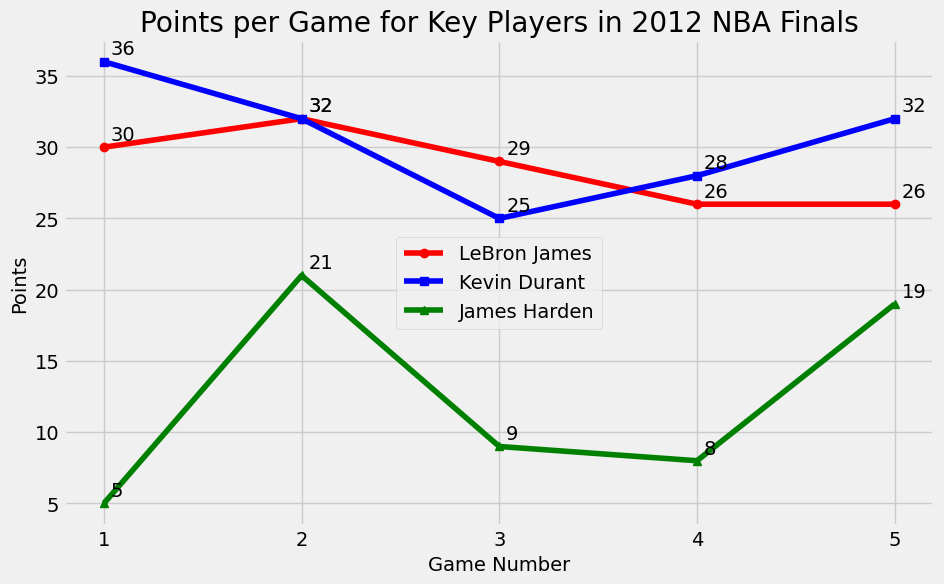

In [18]:
plt.style.use('fivethirtyeight')
# sns.set_style('darkgrid')
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title('Points per Game for Key Players in 2012 NBA Finals')
ax.set_xlabel('Game Number')
ax.set_ylabel('Points')
ax.set_xticks(lebron_df['GAME_NUMBER'])

lebron_plot = (lebron_df, 'LeBron James', 'red', 'o')
durant_plot = (durant_df, 'Kevin Durant', 'blue', 's')
harden_plot = (harden_df, 'James Harden', 'green', '^')

for frame, name, color, marker in [lebron_plot, durant_plot, harden_plot]:
    ax.plot(frame['GAME_NUMBER'], frame['points'], marker=marker, label=name, color=color)
    for _, row in frame.iterrows():
        ax.annotate(str(int(row['points'])), xy=(row['GAME_NUMBER'], row['points']), xytext=(5, 5), textcoords='offset points')

plt.legend()
plt.savefig('../data/points_per_game_key_players.png',)

plt.show()

In [22]:
all_games_df['eFGPercentage'] = (all_games_df['fieldGoalsMade'] + 0.5 * all_games_df['threePointersMade']) / all_games_df['fieldGoalsAttempted']
print(all_games_df[['nameI', 'GAME_NUMBER', 'fieldGoalsMade', 'threePointersMade', 'fieldGoalsAttempted', 'eFGPercentage']].sort_values(by='GAME_NUMBER', ascending=True))

            nameI  GAME_NUMBER  fieldGoalsMade  threePointersMade  \
129     R. Turiaf            1               0                  0   
104     K. Durant            1              12                  4   
105      S. Ibaka            1               5                  0   
106    K. Perkins            1               2                  0   
107  T. Sefolosha            1               2                  0   
..            ...          ...             ...                ...   
23     L. Hayward            5               1                  0   
24        R. Ivey            5               2                  2   
25    N. Mohammed            5               0                  0   
13      K. Durant            5              13                  3   
0        L. James            5               9                  0   

     fieldGoalsAttempted  eFGPercentage  
129                    0            NaN  
104                   20       0.700000  
105                   10       0.500000  
106

In [24]:
all_games_df['minutes'].head(10)

0    44:09
1    28:42
2    34:25
3    34:40
4    33:56
5    23:14
6    10:34
7    16:40
8     4:37
9     3:01
Name: minutes, dtype: str

In [25]:
def convert_string_minutes_to_float(minutes_str):
    if isinstance(minutes_str, str) and ':' in minutes_str:
        minutes, seconds = minutes_str.split(':')
        return int(minutes) + int(seconds) / 60
    return 0.0

In [30]:
all_games_df['minutesPlayed'] = all_games_df['minutes'].apply(convert_string_minutes_to_float)
rotation_df = all_games_df[all_games_df['minutesPlayed'] >= 10]

In [28]:
all_games_df

,gameId,teamId,teamCity,teamName,teamTricode,teamSlug,personId,firstName,familyName,nameI,...,assists,steals,blocks,turnovers,foulsPersonal,points,plusMinusPoints,GAME_NUMBER,eFGPercentage,minutesPlayed
0,0041100405,1610612748,Miami,Heat,MIA,heat,2544,LeBron,James,L. James,...,13,1,2,6,2,26,20.0,5,0.473684,44.150000
1,0041100405,1610612748,Miami,Heat,MIA,heat,2203,Shane,Battier,S. Battier,...,1,1,0,1,4,11,8.0,5,0.687500,28.700000
2,0041100405,1610612748,Miami,Heat,MIA,heat,2547,Chris,Bosh,C. Bosh,...,0,1,2,0,1,24,29.0,5,0.678571,34.416667
3,0041100405,1610612748,Miami,Heat,MIA,heat,2548,Dwyane,Wade,D. Wade,...,3,2,3,1,4,20,25.0,5,0.583333,34.666667
4,0041100405,1610612748,Miami,Heat,MIA,heat,201596,Mario,Chalmers,M. Chalmers,...,7,2,0,4,3,10,25.0,5,0.666667,33.933333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,0041100401,1610612748,Miami,Heat,MIA,heat,202708,Norris,Cole,N. Cole,...,0,0,0,0,0,0,0.0,1,NaN,0.000000
126,0041100401,1610612748,Miami,Heat,MIA,heat,202227,Terrel,Harris,T. Harris,...,0,0,0,0,0,0,0.0,1,NaN,0.000000
127,0041100401,1610612748,Miami,Heat,MIA,heat,436,Juwan,Howard,J. Howard,...,0,0,0,0,0,0,0.0,1,NaN,0.000000
128,0041100401,1610612748,Miami,Heat,MIA,heat,2592,James,Jones,J. Jones,...,0,0,0,0,0,0,0.0,1,NaN,0.000000


In [31]:
rotation_df

,gameId,teamId,teamCity,teamName,teamTricode,teamSlug,personId,firstName,familyName,nameI,...,assists,steals,blocks,turnovers,foulsPersonal,points,plusMinusPoints,GAME_NUMBER,eFGPercentage,minutesPlayed
0,0041100405,1610612748,Miami,Heat,MIA,heat,2544,LeBron,James,L. James,...,13,1,2,6,2,26,20.0,5,0.473684,44.150000
1,0041100405,1610612748,Miami,Heat,MIA,heat,2203,Shane,Battier,S. Battier,...,1,1,0,1,4,11,8.0,5,0.687500,28.700000
2,0041100405,1610612748,Miami,Heat,MIA,heat,2547,Chris,Bosh,C. Bosh,...,0,1,2,0,1,24,29.0,5,0.678571,34.416667
3,0041100405,1610612748,Miami,Heat,MIA,heat,2548,Dwyane,Wade,D. Wade,...,3,2,3,1,4,20,25.0,5,0.583333,34.666667
4,0041100405,1610612748,Miami,Heat,MIA,heat,201596,Mario,Chalmers,M. Chalmers,...,7,2,0,4,3,10,25.0,5,0.666667,33.933333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119,0041100401,1610612748,Miami,Heat,MIA,heat,2617,Udonis,Haslem,U. Haslem,...,0,0,0,1,5,4,-10.0,1,0.333333,28.616667
120,0041100401,1610612748,Miami,Heat,MIA,heat,2548,Dwyane,Wade,D. Wade,...,8,1,0,3,3,19,-6.0,1,0.368421,42.483333
121,0041100401,1610612748,Miami,Heat,MIA,heat,201596,Mario,Chalmers,M. Chalmers,...,6,0,1,1,4,12,-3.0,1,0.857143,35.450000
122,0041100401,1610612748,Miami,Heat,MIA,heat,2547,Chris,Bosh,C. Bosh,...,0,0,0,1,2,10,-16.0,1,0.409091,33.650000


In [35]:
team_efg = rotation_df.groupby(['teamTricode', 'GAME_NUMBER'])['eFGPercentage'].mean().reset_index()
print(team_efg)

  teamTricode  GAME_NUMBER  eFGPercentage
0         MIA            1       0.548006
1         MIA            2       0.503743
2         MIA            3       0.641234
3         MIA            4       0.553947
4         MIA            5       0.552413
5         OKC            1       0.604167
6         OKC            2       0.412388
7         OKC            3       0.435727
8         OKC            4       0.422768
9         OKC            5       0.442494


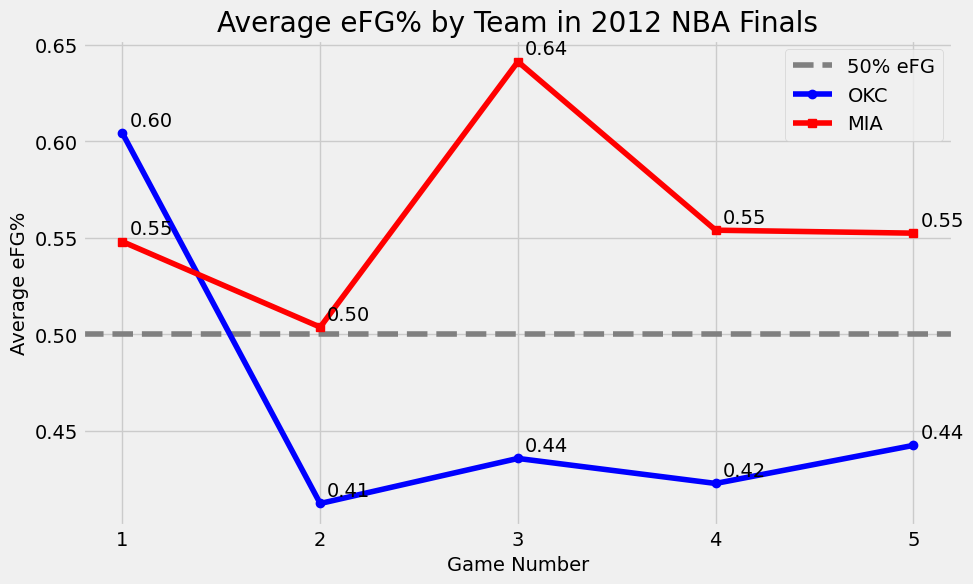

In [40]:
plt.style.use('fivethirtyeight')
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_title('Average eFG% by Team in 2012 NBA Finals')
ax.set_xlabel('Game Number')
ax.set_ylabel('Average eFG%')
ax.set_xticks(team_efg['GAME_NUMBER'].unique())
okc_team_data = (team_efg[team_efg['teamTricode'] == 'OKC'], 'OKC', 'blue', 'o')
mia_team_data = (team_efg[team_efg['teamTricode'] == 'MIA'], 'MIA', 'red', 's')
ax.axhline(0.5, color='gray', linestyle='--', label='50% eFG')


for data, name, color, marker in [okc_team_data, mia_team_data]:
    ax.plot(data['GAME_NUMBER'], data['eFGPercentage'], marker=marker, label=name, color=color)
    for _, row in data.iterrows():
        ax.annotate(f"{row['eFGPercentage']:.2f}", xy=(row['GAME_NUMBER'], row['eFGPercentage']), xytext=(5, 5), textcoords='offset points')
    
ax.legend()
plt.savefig('../data/avg_efg.png')

### This second graph compares both teams' eFG% over the 5 game span. Effective Field Goal Percentage (eFG%) accounts for 3 pointers made in its calculation. The big drop off after Game 1 from the Thunder gives us some more context on how the Heat won so handily. The dashed line represents the average eFG% of a team during the regular season and the Thunder never even came close in the final 4 games. Mean while, the Heat matched or topped it consistently, peaking in Game 3 when they dominated. 